# Pix no Brasil (2020 a 2026): análise exploratória

**Pergunta de negócio:** quanto o Pix cresceu desde o lançamento e quais meios de pagamento ele substituiu?

**Dados:** Banco Central do Brasil (Estatísticas do Pix e Meios de Pagamento), preparados por `src/preparo.py`.

**Atenção a duas fontes diferentes:**
- As tabelas do Pix (transações, municípios, setores) contam o que foi **liquidado no SPI**.
- A tabela de meios de pagamento inclui também o Pix liquidado **fora do SPI** (entre contas da mesma instituição), por isso mostra totais maiores (cerca de 10% a mais em quantidade em 09/2026).

Cada seção abaixo responde a uma pergunta e termina com a conclusão em uma frase.

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

DADOS, IMG = "../data/processed/", "../docs/img/"

# Estilo único para todos os gráficos
AZUL, LARANJA, VERDE, AMARELO, ROSA, ROXO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"
CINZA = "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "xtick.color": CINZA, "ytick.color": CINZA,
    "ytick.left": False, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 14, "font.size": 10, "lines.linewidth": 2, "figure.dpi": 110,
})

def br(x, casas=1):
    "Número no padrão brasileiro: 1.234,5"
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def salvar(nome):
    plt.tight_layout()
    plt.savefig(IMG + nome, dpi=160, bbox_inches="tight")
    plt.show()

## 1. Quanto o Pix cresceu?

In [40]:
mensal = pd.read_csv(DADOS + "pix_mensal.csv", parse_dates=["Data"])
mensal["Ano"] = mensal["Data"].dt.year

anual = mensal.groupby("Ano").agg(Meses=("AnoMes", "count"), Quantidade=("QUANTIDADE", "sum"), Valor=("VALOR", "sum"))
anual["Quantidade (bi)"] = (anual["Quantidade"] / 1e9).round(2)
anual["Valor (R$ tri)"] = (anual["Valor"] / 1e12).round(2)
anual["Ticket médio (R$)"] = (anual["Valor"] / anual["Quantidade"]).round(2)
anual[["Meses", "Quantidade (bi)", "Valor (R$ tri)", "Ticket médio (R$)"]]

,Meses,Quantidade (bi),Valor (R$ tri),Ticket médio (R$)
Ano,,,,
2020,2,0.15,0.13,861.77
2021,12,7.98,4.52,566.75
2022,12,20.35,9.47,465.52
2023,12,36.20,14.47,399.65
2024,12,56.31,22.12,392.83
2025,12,71.32,29.61,415.15
2026,10,69.02,30.08,435.77


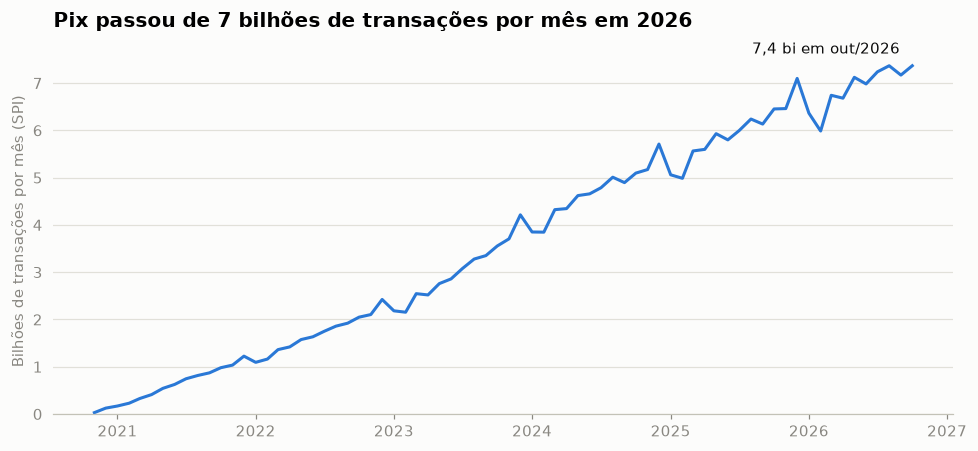

In [41]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(mensal["Data"], mensal["QUANTIDADE"] / 1e9, color=AZUL)
ult = mensal.iloc[-1]
ax.annotate(f"{br(ult.QUANTIDADE / 1e9)} bi em out/2026", (ult.Data, ult.QUANTIDADE / 1e9),
            xytext=(-8, 8), textcoords="offset points", ha="right", color="#0b0b0b")
ax.set_title("Pix passou de 7 bilhões de transações por mês em 2026")
ax.set_ylabel("Bilhões de transações por mês (SPI)", color=CINZA)
ax.set_ylim(0)
salvar("01_crescimento_mensal.png")

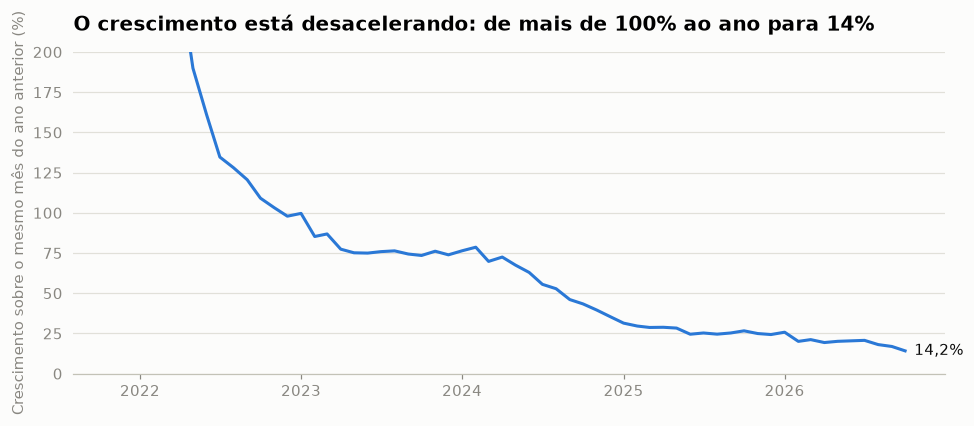

,AnoMes,CrescQtdAnual
23,202210,109.1
35,202310,73.5
47,202410,43.4
59,202510,26.6
71,202610,14.2


In [42]:
cresc = mensal.dropna(subset=["CrescQtdAnual"])
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(cresc["Data"], cresc["CrescQtdAnual"] * 100, color=AZUL)
ax.annotate(f"{br(cresc.CrescQtdAnual.iloc[-1] * 100)}%", (cresc.Data.iloc[-1], cresc.CrescQtdAnual.iloc[-1] * 100),
            xytext=(6, 0), textcoords="offset points", va="center", color="#0b0b0b")
ax.set_title("O crescimento está desacelerando: de mais de 100% ao ano para 14%")
ax.set_ylabel("Crescimento sobre o mesmo mês do ano anterior (%)", color=CINZA)
ax.set_ylim(0, 200)   # corta os primeiros meses, que partem de uma base muito pequena
salvar("02_crescimento_anual.png")
cresc.loc[cresc["Data"].dt.month == 10, ["AnoMes", "CrescQtdAnual"]].assign(CrescQtdAnual=lambda d: (d.CrescQtdAnual * 100).round(1))

**Conclusão:** o Pix saiu de 8 bilhões de transações em 2021 para 71 bilhões em 2025. O crescimento anual caiu de 109% (out/2022) para 14% (out/2026): o produto está amadurecendo, e o crescimento agora vem mais de uso por pessoa do que de novos usuários.

## 2. O crescimento vem de novos usuários ou de mais uso?

In [43]:
ref = mensal[mensal["Data"].dt.month == 10][["AnoMes", "UsuariosPF", "UsuariosPJ", "TransacoesPorUsuario", "TicketMedio"]].copy()
ref["UsuariosPF"] = (ref["UsuariosPF"] / 1e6).round(1)
ref["UsuariosPJ"] = (ref["UsuariosPJ"] / 1e6).round(1)
ref.round(1).rename(columns={"UsuariosPF": "Usuários PF (mi)", "UsuariosPJ": "Usuários PJ (mi)",
                             "TransacoesPorUsuario": "Transações por usuário no mês", "TicketMedio": "Ticket médio (R$)"})

,AnoMes,Usuários PF (mi),Usuários PJ (mi),Transações por usuário no mês,Ticket médio (R$)
11,202110,105.2,7.4,8.7,512.4
23,202210,127.8,10.6,14.8,438.0
35,202310,142.8,13.1,22.8,388.4
47,202410,154.8,15.2,30.0,409.8
59,202510,161.8,16.4,36.2,428.8
71,202610,168.8,19.0,39.2,445.2


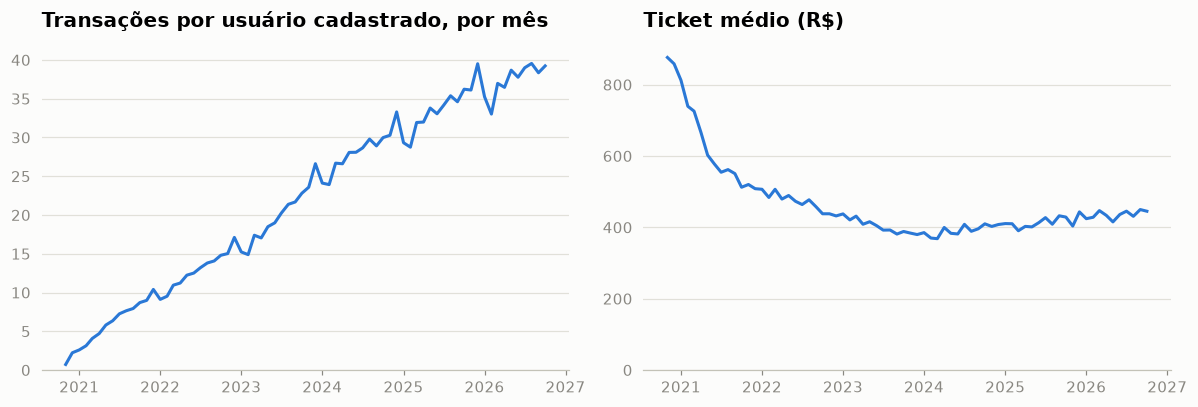

In [44]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8))
eixos[0].plot(mensal["Data"], mensal["TransacoesPorUsuario"], color=AZUL)
eixos[0].set_title("Transações por usuário cadastrado, por mês")
eixos[0].set_ylim(0)
eixos[1].plot(mensal["Data"], mensal["TicketMedio"], color=AZUL)
eixos[1].set_title("Ticket médio (R$)")
eixos[1].set_ylim(0)
salvar("03_uso_e_ticket.png")

**Conclusão:** entre out/2022 e out/2026 os usuários pessoa física cresceram 32% (de 127,8 para 168,8 milhões), enquanto as transações por usuário cresceram 165% (de 14,8 para 39,2 por mês). O crescimento é de **intensidade de uso**. O ticket médio caiu de R$ 567 (2021) para R$ 393 (2024), sinal de que o Pix entrou nas compras pequenas do dia a dia, e voltou a subir para R$ 436 em 2026.

### Cuidado: parte do volume é dinheiro mudando de conta, não pagamento

In [45]:
tit = pd.read_csv(DADOS + "pix_mesma_titularidade_anual.csv")
t = tit[tit["MesmaTitularidade"] == "S"].set_index("Ano")[["PartQtd", "PartValor"]] * 100
t.round(1).rename(columns={"PartQtd": "% das transações", "PartValor": "% do valor"})

,% das transações,% do valor
Ano,,
2020,38.7,49.3
2021,20.2,35.1
2022,16.5,34.5
2023,13.0,35.0
2024,11.2,35.3
2025,10.7,36.7
2026,10.2,38.9


**Conclusão:** em 2026, 10% das transações e 39% do valor do Pix são transferências entre contas do **mesmo titular** (a pessoa ou empresa movendo o próprio dinheiro). Isso infla o valor total e o ticket médio. Conferência: sem essas transferências, set/2025 soma 5,5 bilhões de transações e R$ 1,7 trilhão, os mesmos números que o BCB publica no Relatório de Política Monetária de dez/2025. Por isso, a análise de setores (seção 6) exclui a mesma titularidade.

## 3. Para que o Pix é usado? De transferência entre pessoas a meio de pagamento no comércio

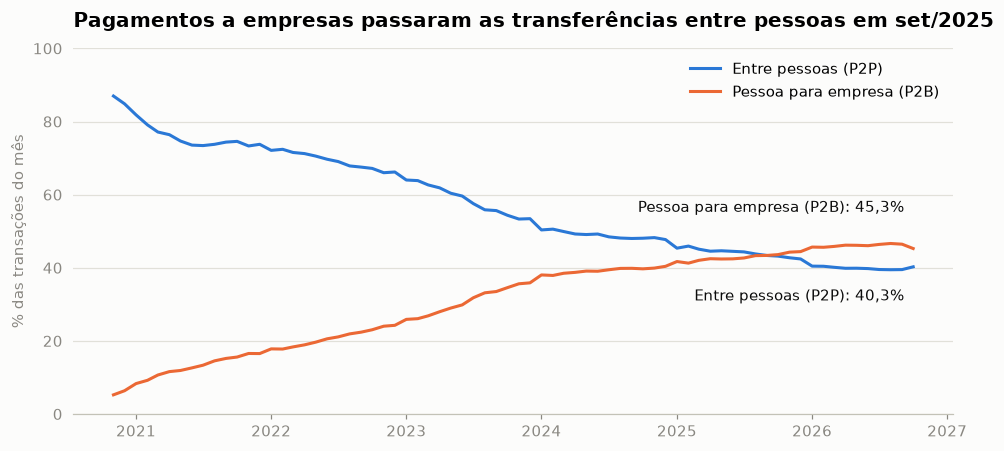

FORMAINICIACAO,Chave Pix (%),Dados da conta (%),QR Code dinâmico (%),QR Code estático (%)
Ano,,,,
2020,NaN,NaN,NaN,NaN
2021,54.6,11.5,3.9,1.8
2022,68.1,15.2,11.6,4.7
2023,55.3,13.0,23.6,7.7
2024,45.1,12.0,34.4,8.1
2025,40.2,11.6,39.6,8.1
2026,37.5,10.4,43.2,8.1


In [46]:
nat = pd.read_csv(DADOS + "pix_natureza_mensal.csv", parse_dates=["Data"])
p = nat.pivot(index="Data", columns="NATUREZA", values="PartQtd") * 100

fig, ax = plt.subplots(figsize=(9, 4.2))
for col, cor, nome in [("P2P", AZUL, "Entre pessoas (P2P)"), ("P2B", LARANJA, "Pessoa para empresa (P2B)")]:
    ax.plot(p.index, p[col], color=cor, label=nome)
    ax.annotate(f"{nome}: {br(p[col].iloc[-1])}%", (p.index[-1], p[col].iloc[-1]), xytext=(-6, 24 if col == "P2B" else -22),
                textcoords="offset points", ha="right", color="#0b0b0b")
ax.set_title("Pagamentos a empresas passaram as transferências entre pessoas em set/2025")
ax.set_ylabel("% das transações do mês", color=CINZA)
ax.set_ylim(0, 100)
ax.legend(frameon=False, loc="upper right")
salvar("04_p2p_vs_p2b.png")

forma = pd.read_csv(DADOS + "pix_forma_iniciacao_mensal.csv")
forma["Ano"] = forma["AnoMes"] // 100
f = forma.groupby(["Ano", "FORMAINICIACAO"])["QUANTIDADE"].sum().unstack()
(f.div(f.sum(axis=1), axis=0) * 100).round(1)[["DICT", "MANU", "QRDN", "QRES"]].rename(
    columns={"DICT": "Chave Pix (%)", "MANU": "Dados da conta (%)", "QRDN": "QR Code dinâmico (%)", "QRES": "QR Code estático (%)"})

**Conclusão:** em 2020, 85% das transações eram entre pessoas. Em 2026, pagamentos de pessoas a empresas são 46% contra 40% entre pessoas, e o QR Code dinâmico (43%) passou a chave Pix (38%) como forma mais comum de iniciar um pagamento. Em **valor**, a maior fatia é entre empresas (B2B, 51% em 2026).

Sobre as siglas: QRDN (QR Code dinâmico) e QRES (QR Code estático) estão definidas no Informe SPI 013/2021 do BCB. DICT é o pagamento iniciado por chave Pix (consulta ao diretório de chaves) e MANU, pela digitação manual dos dados da conta; o informe cita as duas siglas sem expandi-las, e a leitura segue as formas de iniciação descritas pelo BCB. As demais siglas somam menos de 1% das transações e têm leitura provável, ainda sem fonte primária: INIC (iniciador de pagamento, via Open Finance), AUTO (Pix Automático), APDN e APES (Pix por aproximação, com cobrança dinâmica ou estática). As datas em que aparecem na base são compatíveis: INIC desde dez/2021, AUTO e APDN desde jun/2025, APES desde nov/2025.

## 4. O Pix substituiu quais meios de pagamento?

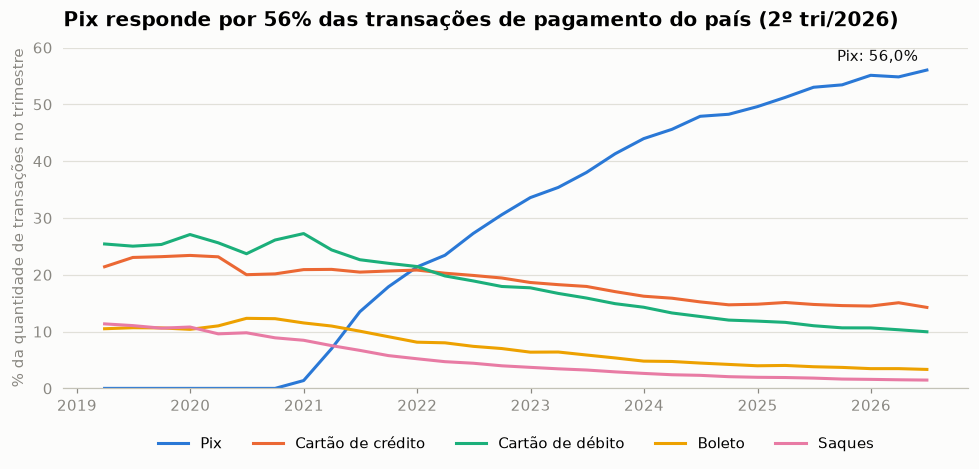

In [47]:
meios = pd.read_csv(DADOS + "meios_pagamento_trimestral.csv", parse_dates=["Trimestre"])
q = meios.pivot(index="Trimestre", columns="Meio", values="Quantidade") / 1e9
part = meios.pivot(index="Trimestre", columns="Meio", values="PartQtd") * 100

fig, ax = plt.subplots(figsize=(9, 4.4))
series = [("Pix", AZUL), ("Cartão de crédito", LARANJA), ("Cartão de débito", VERDE), ("Boleto", AMARELO), ("Saques", ROSA)]
for nome, cor in series:
    ax.plot(part.index, part[nome], color=cor, label=nome)
ax.annotate(f"Pix: {br(part['Pix'].iloc[-1])}%", (part.index[-1], part["Pix"].iloc[-1]), xytext=(-6, 6),
            textcoords="offset points", ha="right", color="#0b0b0b")
ax.set_title("Pix responde por 56% das transações de pagamento do país (2º tri/2026)")
ax.set_ylabel("% da quantidade de transações no trimestre", color=CINZA)
ax.set_ylim(0, 60)
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
salvar("05_participacao_meios.png")

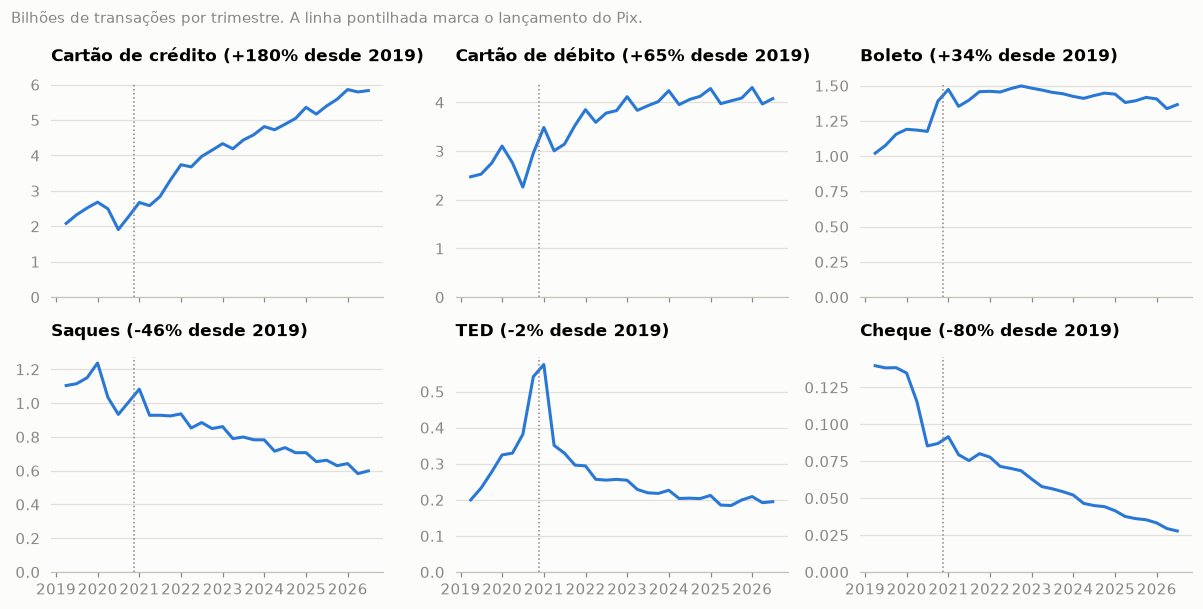

Trimestre,2019-03-31,2020-12-31,2023-03-31,2025-03-31,2026-06-30
Meio,,,,,
Boleto,1.02,1.47,1.47,1.38,1.37
Cartão de crédito,2.08,2.67,4.19,5.17,5.83
Cartão de débito,2.47,3.48,3.84,3.97,4.08
Cartão pré-pago,0.05,0.35,1.48,1.88,1.94
Cheque,0.14,0.09,0.06,0.04,0.03
Convênios,0.91,0.75,0.76,0.70,0.68
DOC,0.05,0.06,0.01,0.00,0.00
Débito direto,1.38,1.70,1.74,2.12,2.27
Pix,0.00,0.18,8.12,17.51,22.93


In [48]:
# Quantidade absoluta: um painel por meio, cada um com sua escala (as ordens de grandeza são muito diferentes)
paineis = ["Cartão de crédito", "Cartão de débito", "Boleto", "Saques", "TED", "Cheque"]
fig, eixos = plt.subplots(2, 3, figsize=(11, 5.6), sharex=True)
for ax, nome in zip(eixos.ravel(), paineis):
    ax.plot(q.index, q[nome], color=AZUL)
    ax.axvline(pd.Timestamp("2020-11-16"), color=CINZA, linewidth=1, linestyle=":")
    var = (q[nome].iloc[-1] / q[nome].iloc[0] - 1) * 100
    ax.set_title(f"{nome} ({var:+.0f}% desde 2019)", fontsize=11)
    ax.set_ylim(0)
fig.suptitle("Bilhões de transações por trimestre. A linha pontilhada marca o lançamento do Pix.", x=0.01, ha="left", fontsize=10, color=CINZA)
salvar("06_outros_meios.png")
q.iloc[[0, 7, 16, 24, -1]].round(2).T

**Conclusão:** o Pix não derrubou tudo o que existia; ele substituiu principalmente o **dinheiro e as transferências antigas**.
- **Caíram:** saques (-46% desde o 1º tri/2019), cheque (-80%), DOC e TEC (extintos). A TED perdeu dois terços das transações desde o pico do fim de 2020.
- **Estagnou:** cartão de débito, parado perto de 4 bilhões de transações por trimestre desde 2023.
- **Continuaram crescendo:** cartão de crédito (+180%) e boleto (+34%).
- Em **valor**, a TED ainda movimenta mais que o Pix (R$ 12,1 tri contra R$ 10,5 tri no 2º tri/2026), porque concentra transferências grandes.

Limite da análise: são séries agregadas. Elas mostram que as quedas coincidem com a alta do Pix, mas não provam sozinhas a causa.

## 5. Onde o Pix é mais usado?

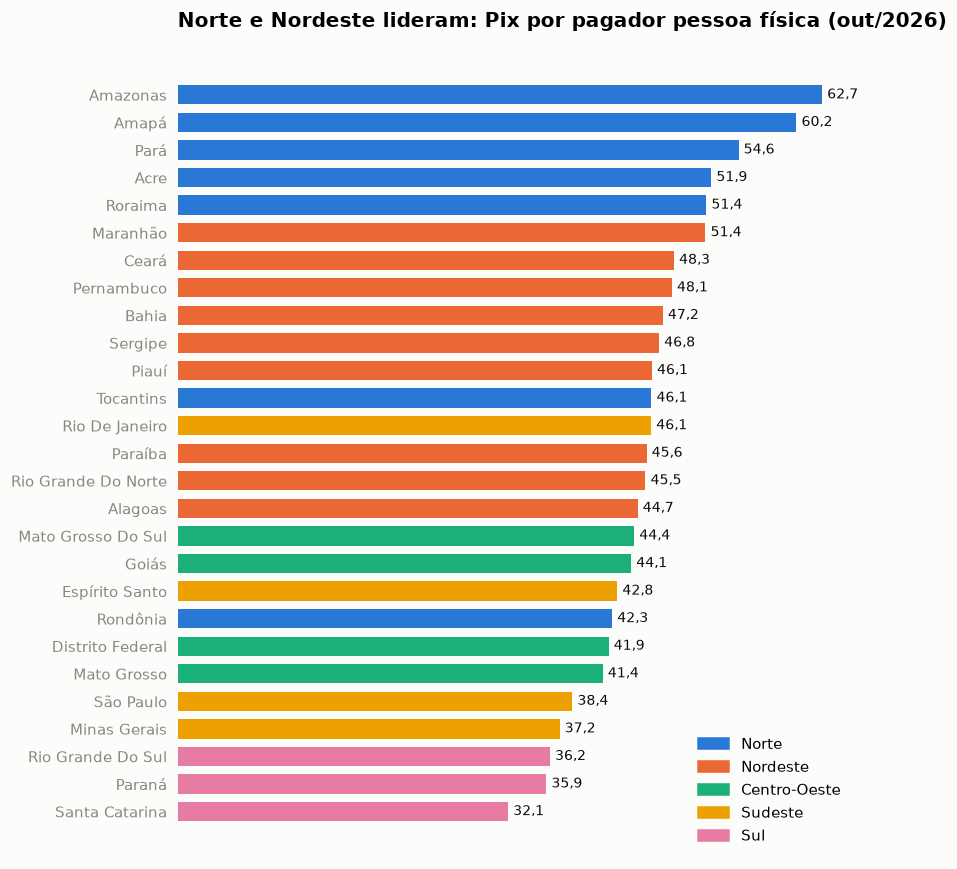

In [49]:
uf = pd.read_csv(DADOS + "pix_uf_mensal.csv")
u = uf[(uf["AnoMes"] == uf["AnoMes"].max()) & (uf["Estado"] != "Não informado")].sort_values("PixPorPagadorPF")
cores = {"NORTE": AZUL, "NORDESTE": LARANJA, "CENTRO-OESTE": VERDE, "SUDESTE": AMARELO, "SUL": ROSA}

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(u["Estado"].str.title(), u["PixPorPagadorPF"], color=u["Regiao"].map(cores), height=0.7)
for y, v in enumerate(u["PixPorPagadorPF"]):
    ax.text(v + 0.5, y, br(v), va="center", fontsize=9, color="#0b0b0b")
ax.grid(False); ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in cores.values()], labels=[r.title() for r in cores],
          frameon=False, loc="lower right")
ax.set_title("Norte e Nordeste lideram: Pix por pagador pessoa física (out/2026)")
salvar("07_uso_por_estado.png")

In [50]:
mun = pd.read_csv(DADOS + "pix_municipio_ultimos_12m.csv")
grandes = mun[mun["PagadoresPF_MediaMensal"] >= 100_000]
cols = ["Municipio", "Estado", "PixMensalPorPagadorPF", "TicketMedioPF"]
print(len(grandes), "municípios com 100 mil pagadores ou mais")
pd.concat([grandes.nlargest(8, "PixMensalPorPagadorPF")[cols], grandes.nsmallest(8, "PixMensalPorPagadorPF")[cols]]).round(1)

214 municípios com 100 mil pagadores ou mais


,Municipio,Estado,PixMensalPorPagadorPF,TicketMedioPF
111,MANAUS,AMAZONAS,66.0,120.0
264,SANTARÉM,PARÁ,62.5,117.7
303,MACAPÁ,AMAPÁ,59.1,127.8
160,ANANINDEUA,PARÁ,58.9,118.9
169,BELÉM,PARÁ,58.5,134.8
633,SÃO JOSÉ DE RIBAMAR,MARANHÃO,55.6,125.9
66,RIO BRANCO,ACRE,55.5,150.0
994,MARACANAÚ,CEARÁ,54.8,125.5
3812,SÃO CAETANO DO SUL,SÃO PAULO,26.0,383.0
4444,JARAGUÁ DO SUL,SANTA CATARINA,28.8,259.3


**Conclusão:** quem mais usa o Pix não são os estados mais ricos. No Amazonas, cada pagador faz 63 Pix por mês; em Santa Catarina, 32. O padrão se inverte no valor: o ticket médio é de R$ 118 no Amazonas e R$ 243 em Santa Catarina. No Norte e Nordeste o Pix funciona como carteira do dia a dia (muitas transações pequenas); no Sul, ele divide espaço com cartões.

Cuidado: a métrica é "Pix por pessoa que pagou", não por habitante. Cruzar com a população do IBGE é um próximo passo.

## 6. Quais setores recebem Pix?

In [51]:
setor = pd.read_csv(DADOS + "pix_setor_porte_anual.csv")
setor = setor[setor["MesmaTitularidade"] == "N"]      # só pagamentos de fato, como faz o BCB
s = setor[setor["Ano"] == 2026].groupby("Setor")[["Quantidade", "Valor"]].sum()
s["% das transações"] = (s["Quantidade"] / s["Quantidade"].sum() * 100).round(1)
s["% do valor"] = (s["Valor"] / s["Valor"].sum() * 100).round(1)
s["Ticket médio (R$)"] = (s["Valor"] / s["Quantidade"]).round(0)
s.sort_values("Quantidade", ascending=False).head(8)[["% das transações", "% do valor", "Ticket médio (R$)"]]

,% das transações,% do valor,Ticket médio (R$)
Setor,,,
"G - Comercio, reparacao de veiculos automotores e motocicletas",27.5,27.7,311.0
"M - Atividades profissionais, cientificas e tecnicas",23.3,9.1,121.0
"R - Artes, cultura, esporte e recreacao",12.4,3.0,75.0
N - Atividades administrativas e servicos complementares,7.9,8.3,327.0
J - Informação e comunicação,7.8,3.2,126.0
"K - Atividades financeiras, de seguros e servicos relacionados",6.8,18.1,826.0
I - Alojamento e alimentacao,5.1,1.9,114.0
S - Outras atividades de servicos,2.2,1.5,205.0


In [52]:
porte = setor.groupby(["Ano", "Porte"])[["Quantidade", "Valor"]].sum()
pq = porte["Quantidade"].unstack()
(pq.div(pq.sum(axis=1), axis=0) * 100).round(1)[["Microempresa", "Pequeno Porte", "Demais"]]

Porte,Microempresa,Pequeno Porte,Demais
Ano,,,
2020,61.1,12.4,26.5
2021,49.8,11.0,39.2
2022,41.2,11.7,47.1
2023,30.9,10.6,58.5
2024,29.7,18.6,51.7
2025,35.5,17.7,46.8
2026,38.3,13.6,48.1


**Conclusão:** o comércio é o setor que mais recebe Pix (27% das transações para empresas em 2026), seguido de atividades profissionais e técnicas (23%) e artes, esporte e recreação (12%, com ticket médio de apenas R$ 75). Micro e pequenas empresas recebem 52% das transações e 36% do valor.

In [53]:
evol = setor.groupby(["Ano", "Setor"])["Quantidade"].sum().unstack()
evol = (evol.div(evol.sum(axis=1), axis=0) * 100).round(1)
evol[[c for c in evol.columns if c[:1] in "GMR"]]

Setor,"G - Comercio, reparacao de veiculos automotores e motocicletas","M - Atividades profissionais, cientificas e tecnicas","R - Artes, cultura, esporte e recreacao"
Ano,,,
2020,39.8,9.0,1.2
2021,38.2,12.1,1.0
2022,36.6,11.1,1.4
2023,29.0,17.4,1.9
2024,24.9,24.0,4.5
2025,25.2,16.2,22.0
2026,27.5,23.3,12.4


**O salto do setor de recreação:** a seção R saiu de 4,5% das transações em 2024 para 22% em 2025. Essa seção inclui a classe CNAE 92 (jogos de azar e apostas), que o BCB usa para identificar empresas de apostas no Estudo Especial 119/2024. O salto coincide com o início do mercado regulado de apostas no Brasil, em 2025, e o perfil bate com apostas (99% de pessoa para empresa, ticket de R$ 75).

In [54]:
sf = pd.read_csv(DADOS + "pix_setor_forma_iniciacao_anual.csv")
f26 = sf[sf["Ano"] == 2026].pivot(index="Setor", columns="FormaIniciacao", values="PartNoSetor").fillna(0) * 100
f26["Transações (bi)"] = sf[sf["Ano"] == 2026].groupby("Setor")["Quantidade"].sum() / 1e9
f26.sort_values("Transações (bi)", ascending=False).head(8)[["QRDN", "QRES", "DICT", "MANU", "Transações (bi)"]].round(1)

FormaIniciacao,QRDN,QRES,DICT,MANU,Transações (bi)
Setor,,,,,
"G - Comercio, reparacao de veiculos automotores e motocicletas",75.1,9.3,12.2,3.1,9.4
"M - Atividades profissionais, cientificas e tecnicas",97.0,0.9,1.6,0.3,8.0
"R - Artes, cultura, esporte e recreacao",95.6,3.2,0.8,0.4,4.2
N - Atividades administrativas e servicos complementares,73.1,19.6,5.4,1.2,2.7
J - Informação e comunicação,86.3,11.3,1.6,0.3,2.7
"K - Atividades financeiras, de seguros e servicos relacionados",91.5,6.0,1.2,1.2,2.3
I - Alojamento e alimentacao,67.5,12.4,15.0,4.9,1.7
S - Outras atividades de servicos,38.2,23.8,29.7,8.1,0.8


**O que a forma de iniciação acrescenta:** em "recreação", 96% dos pagamentos são por QR Code dinâmico, e em "atividades profissionais", 97%. QR dinâmico é gerado por sistema a cada cobrança, então esses dois setores operam de forma quase toda automatizada, e não como um profissional liberal ou um clube recebendo por chave Pix. Para comparar: em "outras atividades de serviços", a chave Pix responde por 30% e o QR dinâmico por 38%.

Isso reforça a hipótese, mas não a fecha: o comércio também tem 75% em QR dinâmico, ou seja, cobrança automatizada não é exclusiva de apostas nem de intermediadores.

É uma **hipótese forte, não uma prova**: a base não abre a seção R por classe, e o mesmo estudo do BCB mostra que, em 2024, a maior parte do dinheiro de apostas ia para empresas registradas fora da CNAE 92. O mesmo vale para "atividades profissionais", cujo peso sugere a presença de intermediadores de pagamento.

## 7. Quem domina as chaves Pix?

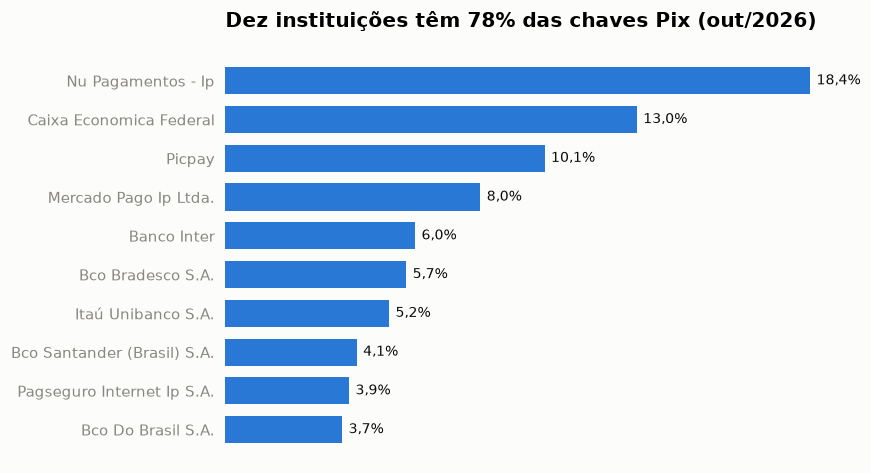

,Data,Instituicoes,ChavesTotal,HHI,Top5
11,2021-10-31,744,348.0,1100.0,61.6
23,2022-10-31,776,523.0,998.0,58.9
35,2023-10-31,809,675.0,933.0,57.6
47,2024-10-31,888,806.0,891.0,56.3
59,2025-10-31,898,901.0,880.0,55.9
71,2026-10-31,854,1021.0,840.0,55.5


In [55]:
inst = pd.read_csv(DADOS + "pix_chaves_instituicao_ultimo_mes.csv").head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(inst["Nome"].str.title(), inst["Part"] * 100, color=AZUL, height=0.7)
for y, v in enumerate(inst["Part"] * 100):
    ax.text(v + 0.2, y, f"{br(v)}%", va="center", fontsize=9, color="#0b0b0b")
ax.grid(False); ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
ax.set_title("Dez instituições têm 78% das chaves Pix (out/2026)")
salvar("08_chaves_instituicoes.png")

conc = pd.read_csv(DADOS + "pix_chaves_concentracao_mensal.csv")
conc[conc["Data"].str[5:7] == "10"].assign(ChavesTotal=lambda d: (d.ChavesTotal / 1e6).round(0), HHI=lambda d: d.HHI.round(0), Top5=lambda d: (d.Top5 * 100).round(1))

**Conclusão:** há 1,02 bilhão de chaves cadastradas. As instituições de pagamento (fintechs) detêm 51% delas, contra 32% dos bancos múltiplos. A concentração vem caindo: as cinco maiores tinham 67% das chaves em 2020 e têm 56% em 2026, e o índice HHI caiu de 1.213 para 840 (abaixo de 1.500 costuma ser lido como mercado pouco concentrado).

Cuidado: chave cadastrada não é o mesmo que conta mais usada. Segundo o Manual Operacional do DICT, uma pessoa física pode ter até cinco chaves por conta e uma pessoa jurídica, até vinte.

## 8. E as fraudes?

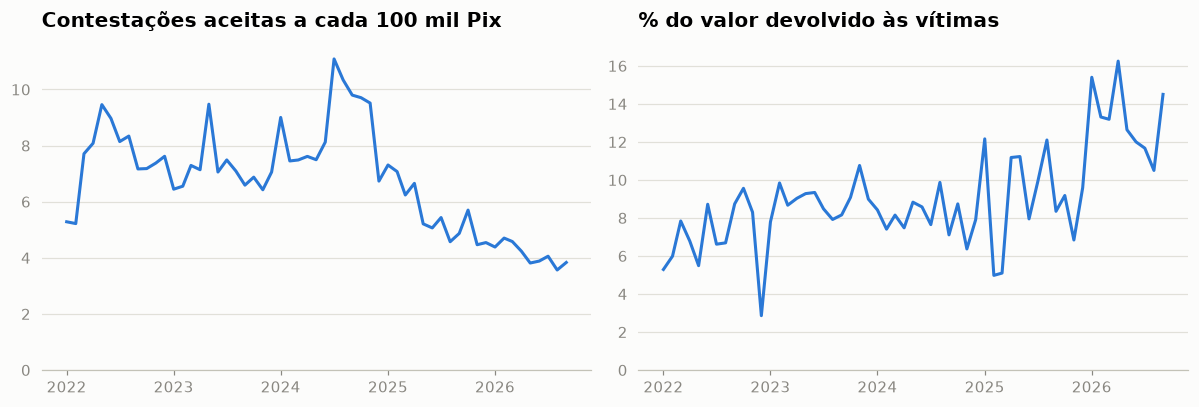

,Meses,Contestados,Aceitas,Valor aceito (R$ bi),% devolvido,% não devolvido por falta de saldo,Ticket médio da fraude (R$)
Ano,,,,,,,
2022,12,2145114,1555898,3.02,6.3,57.4,1944.0
2023,12,4555525,2574112,4.35,9.0,56.6,1691.0
2024,12,12294897,4912210,6.69,8.1,61.8,1361.0
2025,12,22233556,3933705,7.77,9.0,52.3,1975.0
2026,9,27593064,2526408,5.74,13.4,48.2,2271.0


In [56]:
fr = pd.read_csv(DADOS + "pix_fraudes_med.csv", parse_dates=["Data"])
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8))
eixos[0].plot(fr["Data"], fr["Qtdecontestacoesaceitasacada100mil"], color=AZUL)
eixos[0].set_title("Contestações aceitas a cada 100 mil Pix")
eixos[0].set_ylim(0)
eixos[1].plot(fr["Data"], fr["PercentualdeDevolucao"], color=AZUL)
eixos[1].set_title("% do valor devolvido às vítimas")
eixos[1].set_ylim(0)
salvar("09_fraudes.png")

fr["Ano"] = fr["Data"].dt.year
a = fr.groupby("Ano").agg(Meses=("AnoMes", "count"), Contestados=("QtdePixcontestados", "sum"), Aceitas=("Qtdecontestacoesaceitas", "sum"),
                          ValorAceito=("ValorPixcontestadosaceitos", "sum"), DevInt=("ValorPixdevolvidosintegralmente", "sum"),
                          DevPar=("ValorPixdevolvidosparcialmente", "sum"), SemSaldo=("ValorPixnaodevolvidossaldoinsuficiente", "sum"))
a["Valor aceito (R$ bi)"] = (a["ValorAceito"] / 1e9).round(2)
a["% devolvido"] = ((a["DevInt"] + a["DevPar"]) / a["ValorAceito"] * 100).round(1)
a["% não devolvido por falta de saldo"] = (a["SemSaldo"] / a["ValorAceito"] * 100).round(1)
a["Ticket médio da fraude (R$)"] = (a["ValorAceito"] / a["Aceitas"]).round(0)
a[["Meses", "Contestados", "Aceitas", "Valor aceito (R$ bi)", "% devolvido", "% não devolvido por falta de saldo", "Ticket médio da fraude (R$)"]]

**Conclusão:** a fraude é rara em proporção (cerca de 4 contestações aceitas a cada 100 mil Pix em 2026, contra 7,5 em 2022) e a taxa vem caindo. Mas o valor absoluto cresce (R$ 7,8 bilhões em contestações aceitas em 2025) e **a recuperação é baixa**: só 13% do valor volta para a vítima em 2026, e cerca de metade não é devolvida porque a conta do golpista já está sem saldo (48% em 2026, 52% em 2025).

Observação: as contestações quase triplicaram em out/2025 (de 1,2 para 3,5 milhões por mês) sem aumento parecido nas aceitas. A causa é uma mudança de canal: em 1º/10/2025 entrou no ar o autoatendimento do MED (o "botão de contestação" no aplicativo do banco), que tornou a contestação muito mais fácil. Por isso, o número de contestações **não é comparável** antes e depois dessa data; para medir a evolução da fraude, use as contestações aceitas. A devolução subiu de 9% do valor em 2025 para 13% em 2026, o que é compatível com o objetivo da medida (bloquear o dinheiro mais rápido), sem provar a causa.

## 9. Existe sazonalidade?

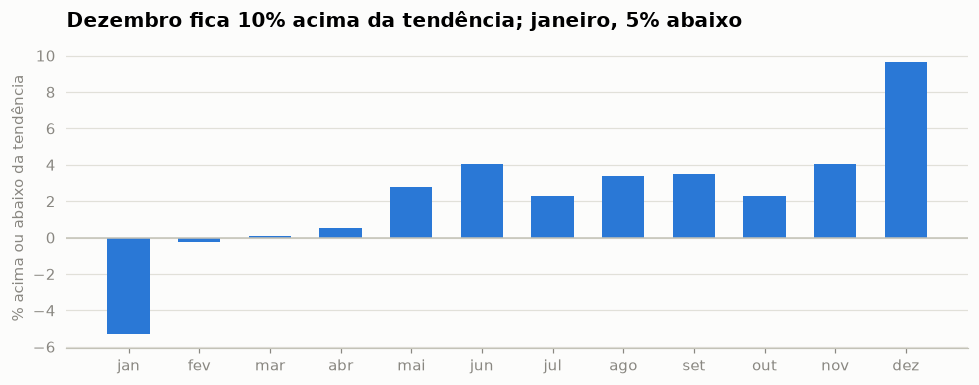

Data
jan   -5.3
fev   -0.3
mar    0.1
abr    0.5
mai    2.8
jun    4.1
jul    2.3
ago    3.4
set    3.5
out    2.3
nov    4.0
dez    9.6
Name: Indice, dtype: float64

In [57]:
m = mensal.copy()
m["Tendencia"] = m["QtdPorDia"].rolling(12, center=True).mean()   # média móvel de 12 meses
m["Indice"] = m["QtdPorDia"] / m["Tendencia"]
saz = m.groupby(m["Data"].dt.month)["Indice"].mean()
nomes = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(nomes, (saz - 1) * 100, color=AZUL, width=0.6)
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_title("Dezembro fica 10% acima da tendência; janeiro, 5% abaixo")
ax.set_ylabel("% acima ou abaixo da tendência", color=CINZA)
salvar("10_sazonalidade.png")
((saz - 1) * 100).round(1).rename(index=dict(enumerate(nomes, 1)))

**Conclusão:** usando transações por dia (para não confundir com meses mais curtos), dezembro fica cerca de 10% acima da tendência e janeiro 5% abaixo. Os demais meses variam pouco. Método simples: razão entre o valor do mês e a média móvel de 12 meses; como a série ainda cresce rápido, o resultado é uma aproximação.

## Recomendações

1. **Comércio e adquirência:** o Pix já é o principal meio de pagamento em quantidade e parou o crescimento do débito. Quem vende deve tratar o QR Code dinâmico como forma padrão de cobrança, e quem vive de taxa de débito precisa rever a receita.
2. **Bancos e fintechs:** o crescimento agora vem de uso por pessoa, não de novos usuários. A disputa é por ser a conta principal, e o Norte e o Nordeste são os mercados de maior intensidade de uso.
3. **Crédito:** o cartão de crédito seguiu crescendo ao lado do Pix. Produtos que juntam os dois (como parcelamento no Pix) atacam o espaço que o Pix ainda não ocupa.
4. **Segurança:** a prioridade é velocidade de bloqueio. Cerca de metade do valor fraudado se perde porque o dinheiro sai da conta de destino antes da contestação.

## Limitações
- Dados agregados: não há transações individuais, horário nem perfil detalhado de quem paga.
- Tabelas do Pix cobrem o SPI; a de meios de pagamento inclui também o que é liquidado fora do SPI.
- Uso por estado e município é medido por pessoa que pagou, não por habitante.
- A composição dos setores "recreação" e "atividades profissionais" é hipótese: a base não abre a seção CNAE por classe.
- Valor total e ticket médio incluem transferências entre contas do mesmo titular (39% do valor em 2026), exceto na análise de setores.